# Telecom Customer Analytics EDA
Reproducible analysis against `telecom_analytics.db`.

In [1]:
import sys
print("Python executable:", sys.executable)

%pip install matplotlib seaborn pandas numpy

Python executable: c:\Users\HARSH\AppData\Local\Programs\Python\Python311\python.exe
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import sqlite3, pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
ROOT=Path.cwd().parent if Path.cwd().name=='python' else Path.cwd()
DB=ROOT/'telecom_analytics.db'
con=sqlite3.connect(DB)
customers=pd.read_sql('select * from customers',con,parse_dates=['signup_date','churn_date'])
transactions=pd.read_sql('select * from transactions',con,parse_dates=['transaction_date'])
usage=pd.read_sql('select * from usage',con,parse_dates=['usage_date'])
complaints=pd.read_sql('select * from complaints',con,parse_dates=['complaint_date'])
services=pd.read_sql('select * from services',con)
segments=pd.read_sql('select * from customer_segments',con)
risk=pd.read_sql('select * from high_risk_customers',con)
con.close()
customers.head()

,customer_id,gender,age,city,state,region,signup_date,tenure_months,customer_type,contract_type,payment_method,monthly_income,occupation,marital_status,dependents,churn_flag,churn_date
0,C000001,Male,23,Pune,Maharashtra,West,2024-02-27,30,Consumer,Prepaid,Auto Debit,115000.0,Salaried,Married,1,0,NaT
1,C000002,Female,18,Kolkata,West Bengal,East,2023-12-07,32,Consumer,Annual,UPI,76800.0,Other,Single,0,0,NaT
2,C000003,Male,25,Chennai,Tamil Nadu,South,2022-04-23,52,Consumer,Monthly,Credit Card,99600.0,Other,Single,0,1,2026-03-23
3,C000004,Male,39,Lucknow,Uttar Pradesh,North,2022-07-04,49,Consumer,Two-Year,Credit Card,50200.0,Business,Married,1,0,NaT
4,C000005,Male,49,Lucknow,Uttar Pradesh,North,2024-07-11,25,Consumer,Monthly,Net Banking,46300.0,Salaried,Married,1,1,2026-03-29


## KPI snapshot

In [3]:
kpis={'Total customers':len(customers),'Active customers':int((customers.churn_flag==0).sum()),'Churn rate %':round(customers.churn_flag.mean()*100,2),'Paid revenue':round(transactions.loc[transactions.payment_status=='Paid','amount'].sum(),2),'Complaints':len(complaints),'High-risk customers':int((risk.risk_level=='High').sum())}
pd.Series(kpis)

Total customers        1.200000e+04
Active customers       9.077000e+03
Churn rate %           2.436000e+01
Paid revenue           1.944245e+08
Complaints             2.630000e+03
High-risk customers    1.311000e+03
dtype: float64

## Revenue trend

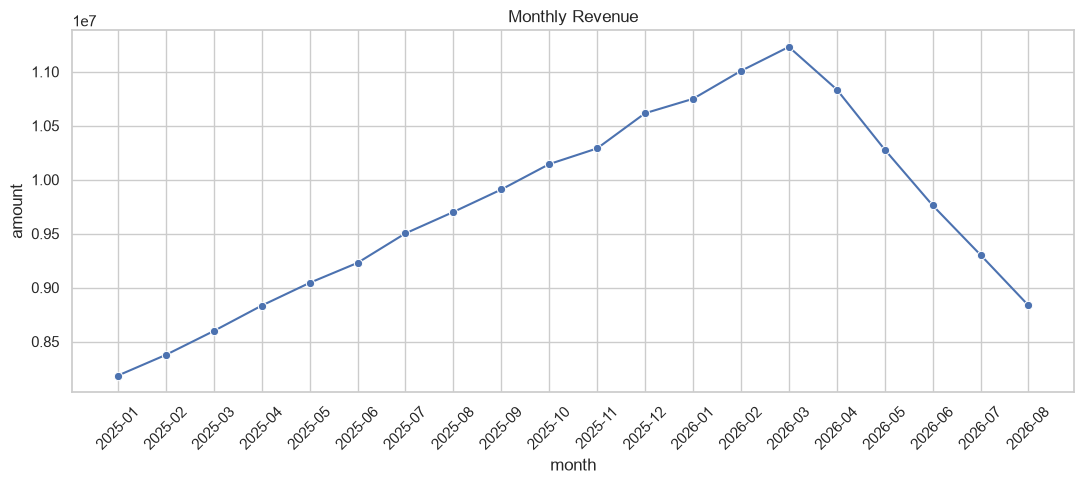

In [4]:
monthly=transactions[transactions.payment_status=='Paid'].assign(month=lambda x:x.transaction_date.dt.to_period('M').astype(str)).groupby('month',as_index=False).amount.sum()
sns.set_theme(style='whitegrid'); plt.figure(figsize=(11,5)); sns.lineplot(data=monthly,x='month',y='amount',marker='o'); plt.xticks(rotation=45); plt.title('Monthly Revenue'); plt.tight_layout(); plt.show()

## Churn drivers

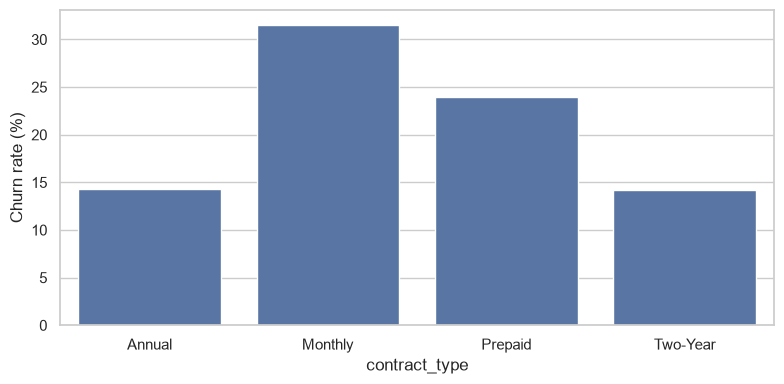

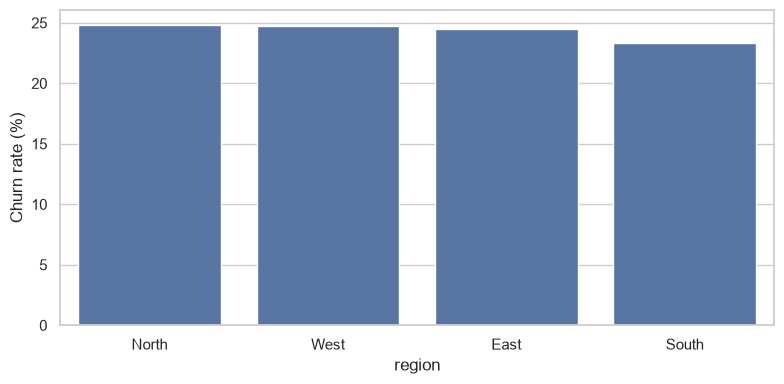

In [5]:
contract=customers.groupby('contract_type',as_index=False).churn_flag.mean(); contract['churn_rate_pct']=100*contract.churn_flag
region=customers.groupby('region',as_index=False).churn_flag.mean(); region['churn_rate_pct']=100*region.churn_flag
fig,ax=plt.subplots(figsize=(8,4)); sns.barplot(data=contract,x='contract_type',y='churn_rate_pct',ax=ax); ax.set_ylabel('Churn rate (%)'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); sns.barplot(data=region.sort_values('churn_rate_pct',ascending=False),x='region',y='churn_rate_pct',ax=ax); ax.set_ylabel('Churn rate (%)'); plt.tight_layout(); plt.show()

## Complaint relationship

In [6]:
cc=complaints.groupby('customer_id').size().rename('complaint_count'); x=customers.set_index('customer_id').join(cc).fillna({'complaint_count':0}).reset_index(); x.groupby('churn_flag').complaint_count.agg(['mean','median','count'])

,mean,median,count
churn_flag,,,
0,0.172193,0.0,9077
1,0.365036,0.0,2923


## Segmentation and high-risk customers

In [7]:
display(segments.groupby('segment').agg(customers=('customer_id','count'),churn_rate=('churn_flag','mean'),revenue=('total_revenue','sum')).sort_values('customers',ascending=False))
display(risk.groupby('risk_level').size().rename('customers'))

,customers,churn_rate,revenue
segment,,,
Low Value Loyal,3307,0.000000,27333177.12
Developing Customers,3112,0.000000,45259428.98
High Value Loyal,2500,0.000000,82918574.24
Low Value At Risk,2083,1.000000,14518072.13
High Value At Risk,767,1.000000,23413221.75
New Customers,231,0.316017,982017.40


risk_level
High      1311
Low       5226
Medium    5463
Name: customers, dtype: int64